# Outlier Detection, Outlier Handling & Missing Value Analysis

## Objectives of this Notebook

1. Detect unusual observations using six outlier detection methods: IQR, Z-score, Modified Z-score (MAD), Isolation Forest, Local Outlier Factor (LOF), and Mahalanobis Distance.
2. Compare outlier detection results and identify observations flagged by multiple methods.
3. Study the effect of outlier handling using Winsorization, log transformation, and outlier removal.
4. Analyze missing values in the processed datasets.
5. Investigate whether review-comment availability is associated with customer ratings and delivery lateness.
6. Conduct a masking experiment by hiding 15% of known product measurements and comparing Mean, Category Median, KNN, and Iterative (MICE) imputation using MAE and RMSE.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2, chi2_contingency
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


# 1.Load processed datasets

In [9]:
master_orders = pd.read_csv("../PROCESSED_DATA/master_orders.csv")
master_sellers = pd.read_csv("../PROCESSED_DATA/master_sellers.csv")
cleaned_products = pd.read_csv("../PROCESSED_DATA/cleaned_products.csv")
cleaned_items = pd.read_csv("../PROCESSED_DATA/cleaned_items.csv")
cleaned_reviews = pd.read_csv("../PROCESSED_DATA/cleaned_reviews.csv")

datasets = {
    "master_orders": master_orders,
    "master_sellers": master_sellers,
    "cleaned_products": cleaned_products,
    "cleaned_items": cleaned_items,
    "cleaned_reviews": cleaned_reviews
}

for name, data in datasets.items():
    print(f"{name} shape: {data.shape}")

master_orders shape: (99441, 59)
master_sellers shape: (3095, 25)
cleaned_products shape: (32951, 11)
cleaned_items shape: (112650, 10)
cleaned_reviews shape: (98673, 7)


### 1.1 Initial Dataset Inspection

The initial inspection checks the available columns, data types and missing values. This helps confirm that the processed files have the expected structure before applying statistical methods.

In [10]:
for name, data in datasets.items():
    print("\n" + "=" * 65)
    print(name.upper())
    print("=" * 65)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Total missing values:", data.isnull().sum().sum())


MASTER_ORDERS
Shape: (99441, 59)
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'primary_seller_id', 'primary_product_id', 'primary_category', 'total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'shipping_limit_date', 'order_total_value', 'freight_ratio', 'payment_total', 'max_installments', 'payment_methods_count', 'primary_payment_type', 'review_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'has_comment', 'seller_zip_code_prefix', 'seller_city', 'seller_state', 'cust_lat', 'cust_lng', 'seller_lat', 'seller_lng', 'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'estimated_delivery_days', 'da

## 2. Outlier Detection

### Purpose

An outlier is an observation that differs considerably from the majority of the data. In the DELTA project, unusual values may represent genuine high-value orders, unusually heavy products, long delivery times, or data-quality problems.

Outliers should not be removed automatically. They must first be detected and investigated because genuine extreme deliveries and high-value transactions may contain important business information.

The following six methods are implemented:

1. **IQR:** Identifies values outside the lower and upper quartile fences.
2. **Z-score:** Measures how many standard deviations a value is from the mean.
3. **Modified Z-score (MAD):** Uses the median and median absolute deviation, making it more robust to extreme values.
4. **Isolation Forest:** Uses random trees to isolate unusual observations.
5. **Local Outlier Factor (LOF):** Identifies observations with lower local density than their neighbours.
6. **Mahalanobis Distance:** Measures unusual combinations of variables while considering correlations between them.

### 2.1 Selection of Numerical Variables

Outlier detection is performed on relevant numerical variables from the order, item and product datasets. Only columns that exist in the corresponding processed dataset are selected.

In [11]:
# Relevant order-level variables
order_outlier_candidates = [
    "total_price", "total_freight", "total_weight_g",
    "total_volume_cm3", "approval_hours",
    "seller_handling_days", "carrier_transit_days",
    "total_delivery_days", "days_late", "distance_km"
]

# Relevant item-level variables
item_outlier_candidates = [
    "price", "freight_value", "product_weight_g",
    "product_volume_cm3"
]

# Relevant product-level variables
product_outlier_candidates = [
    "product_name_length", "product_description_length",
    "product_photos_qty", "product_weight_g",
    "product_length_cm", "product_height_cm",
    "product_width_cm", "product_volume_cm3"
]

def available_numeric_data(data, candidates):
    selected = [c for c in candidates if c in data.columns]
    result = data[selected].apply(pd.to_numeric, errors="coerce")
    return result, selected

orders_numeric, order_columns = available_numeric_data(
    master_orders, order_outlier_candidates
)
items_numeric, item_columns = available_numeric_data(
    cleaned_items, item_outlier_candidates
)
products_numeric, product_columns = available_numeric_data(
    cleaned_products, product_outlier_candidates
)

outlier_datasets = {
    "Orders": orders_numeric,
    "Items": items_numeric,
    "Products": products_numeric
}

print("Order variables:", order_columns)
print("Item variables:", item_columns)
print("Product variables:", product_columns)

Order variables: ['total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'days_late', 'distance_km']
Item variables: ['price', 'freight_value', 'product_weight_g', 'product_volume_cm3']
Product variables: ['product_name_length', 'product_description_length', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_volume_cm3']


### 2.2 Visual Identification of Outliers Using Boxplots

Boxplots provide a visual indication of extreme observations. Points beyond the whiskers are potential outliers according to the boxplot rule; they are not automatically errors.

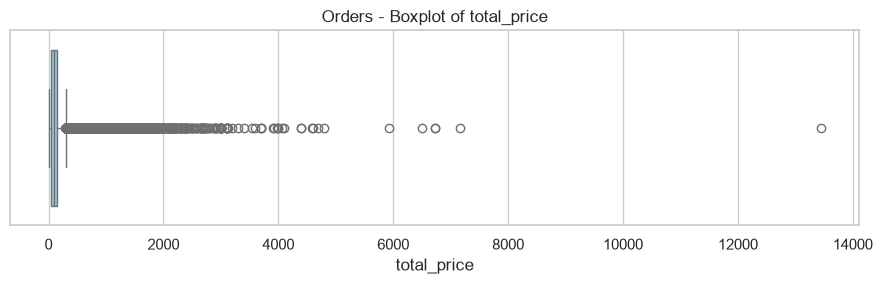

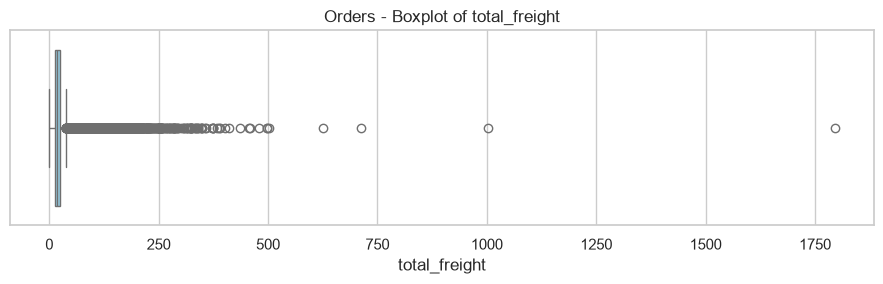

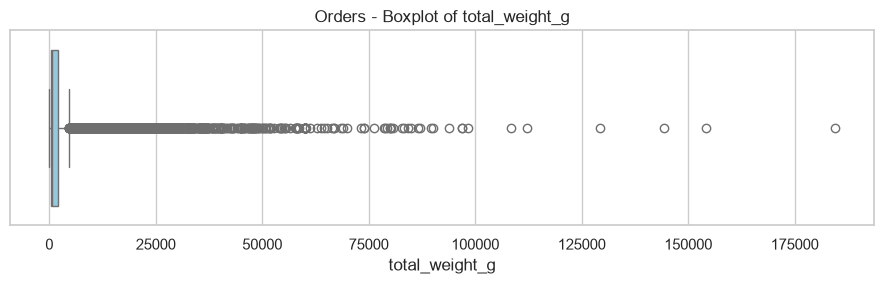

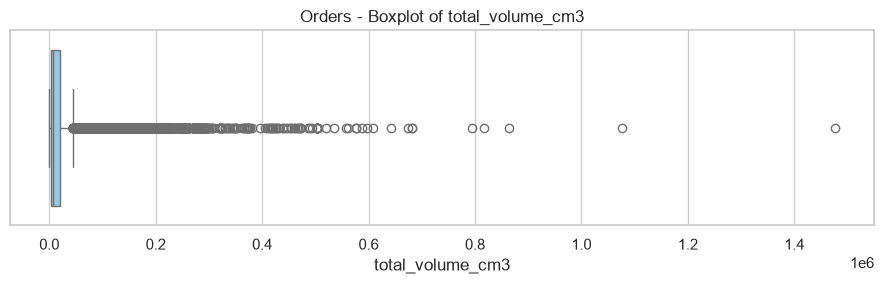

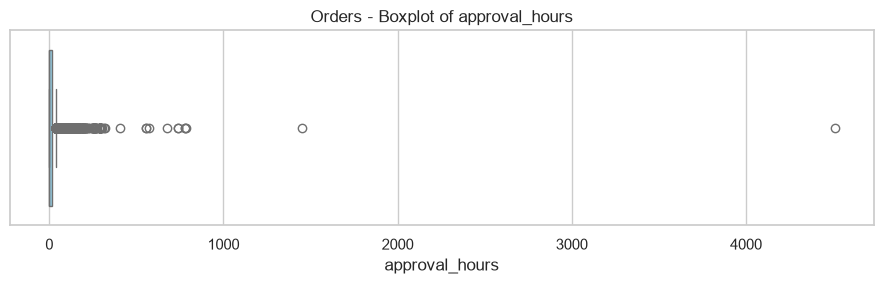

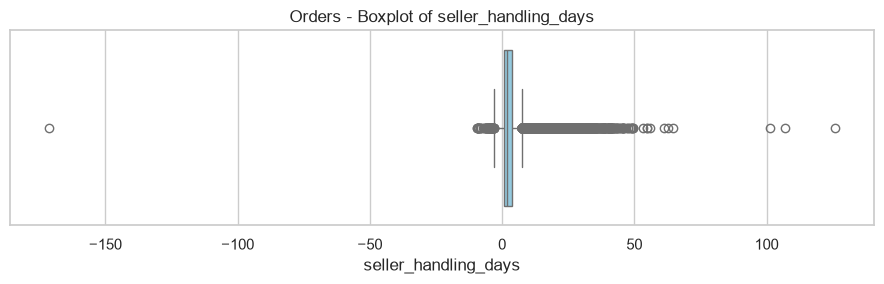

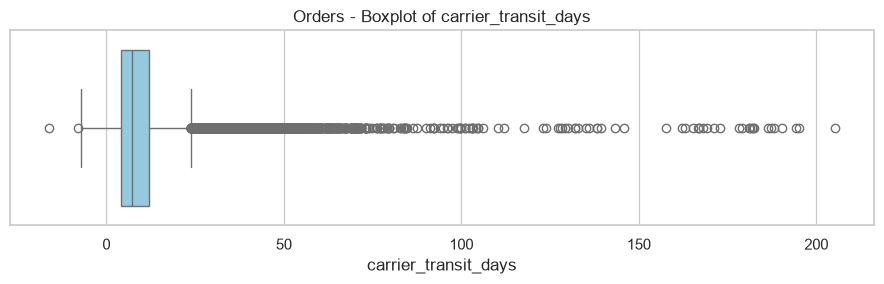

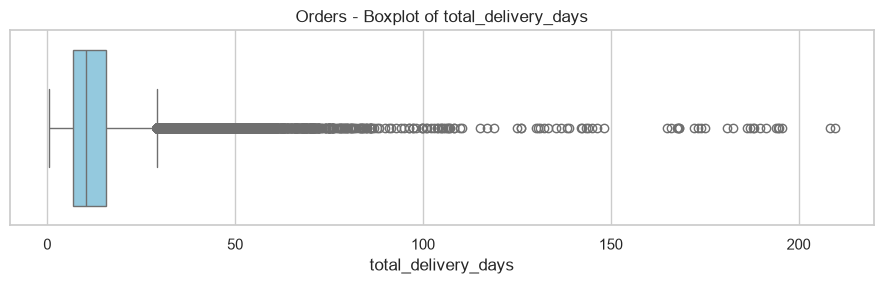

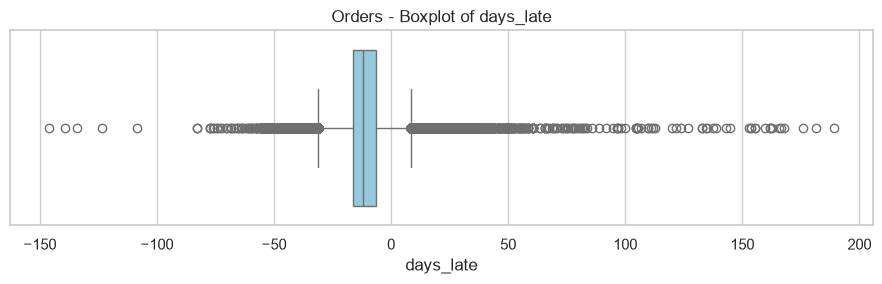

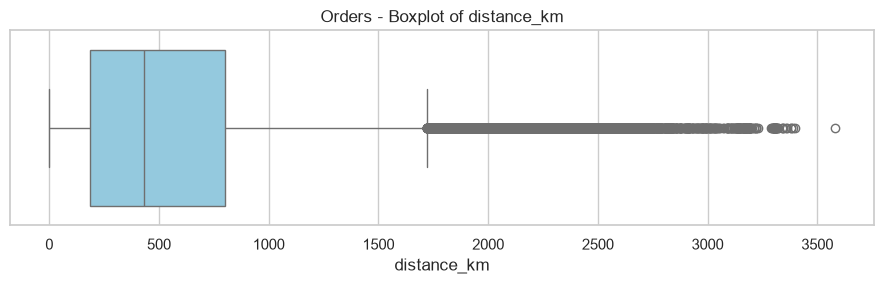

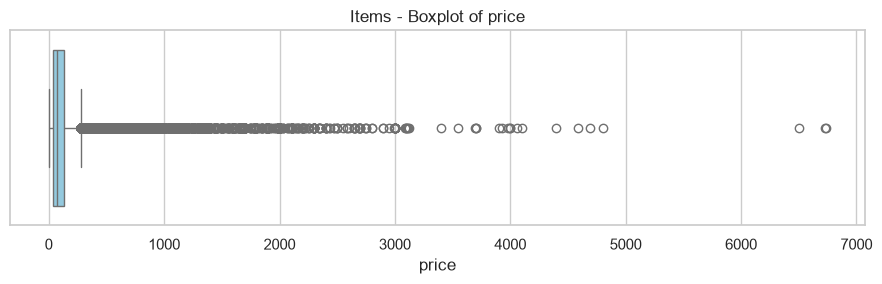

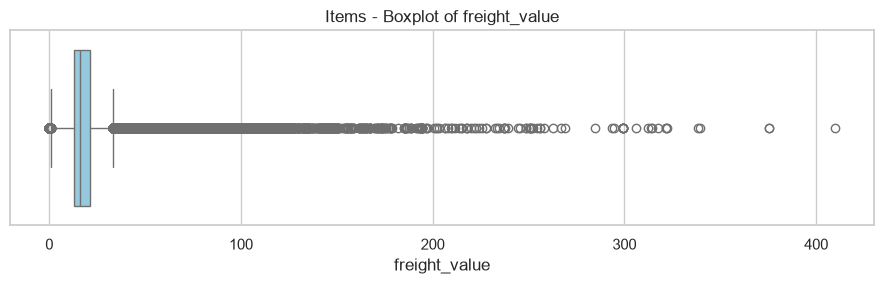

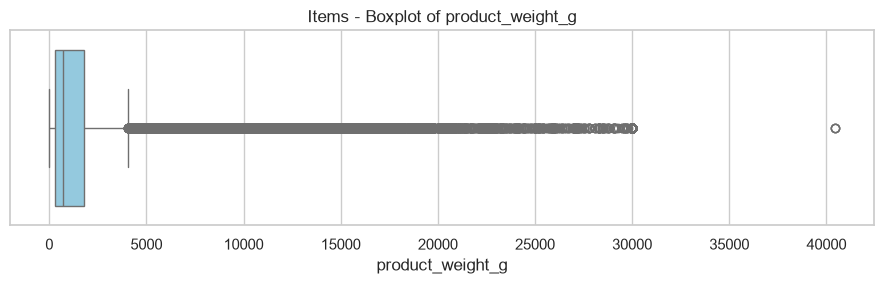

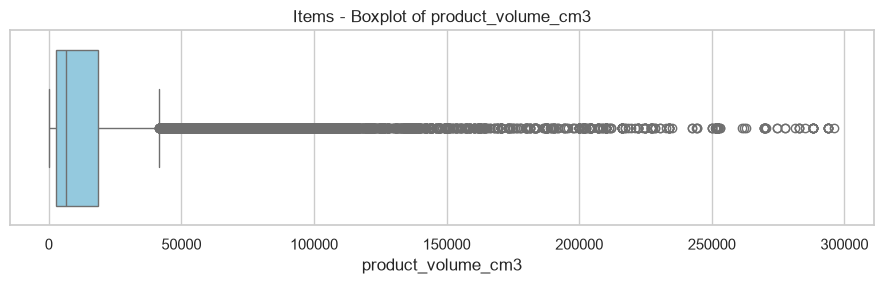

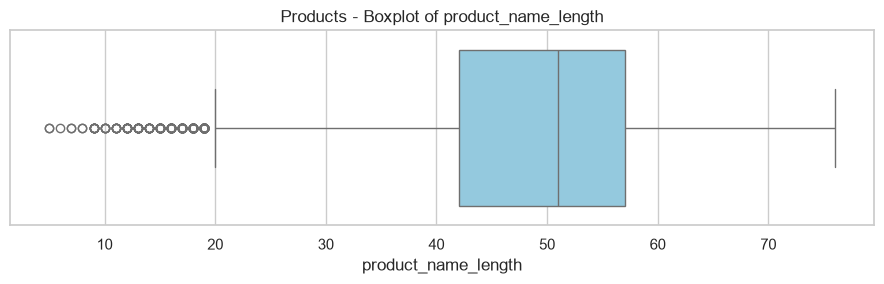

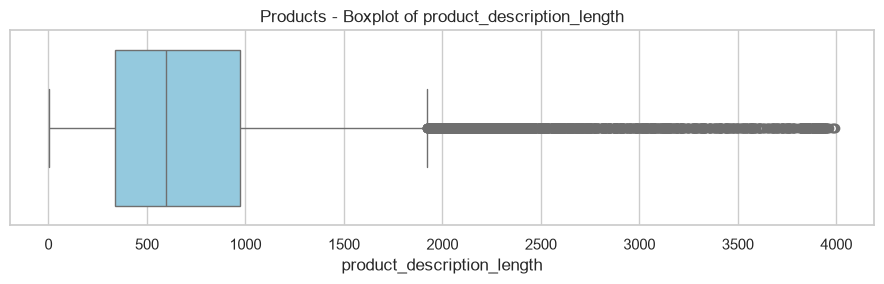

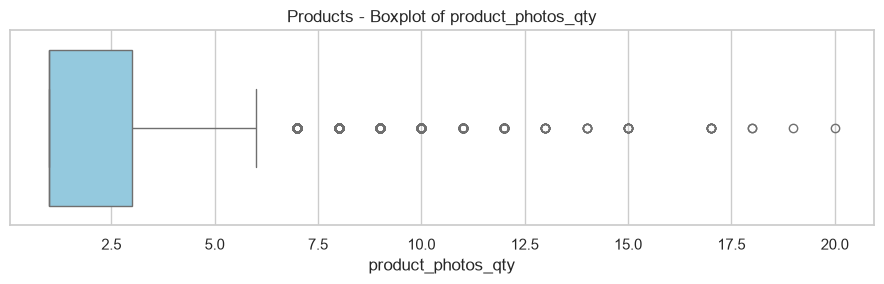

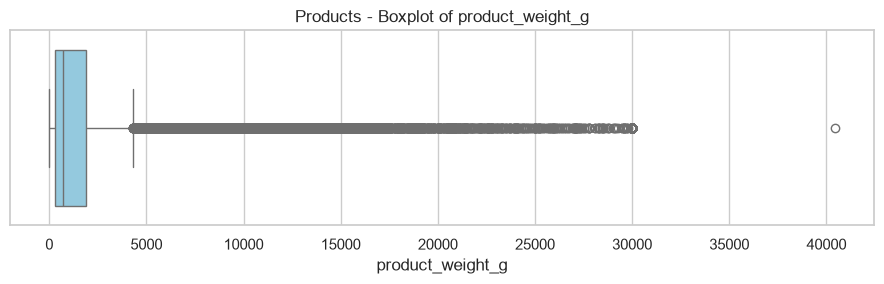

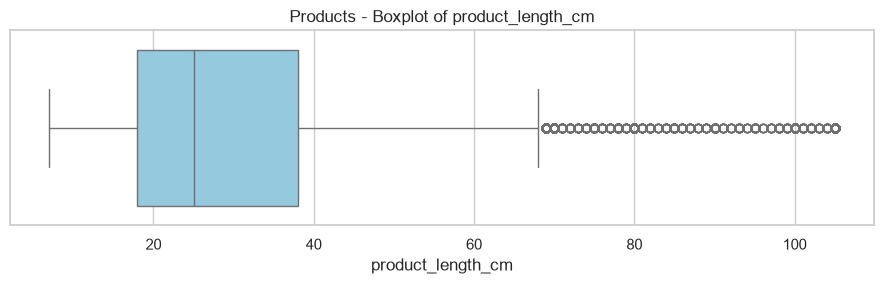

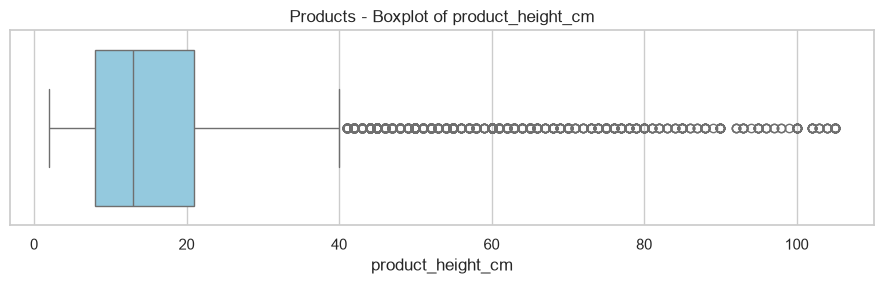

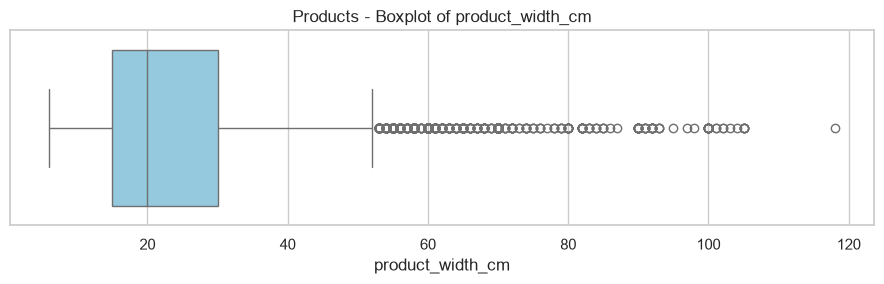

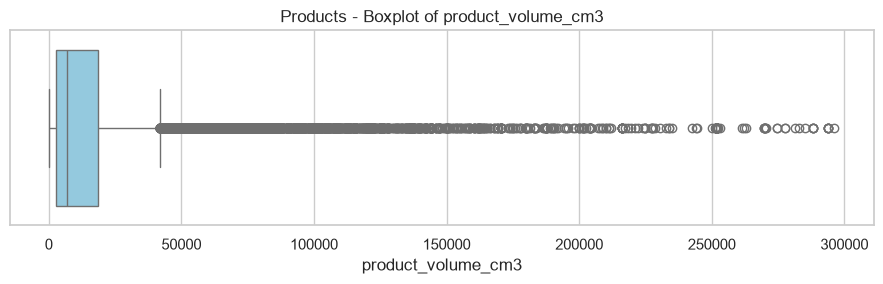

In [12]:
for dataset_name, data in outlier_datasets.items():
    for column in data.columns:
        plt.figure(figsize=(9, 3))
        sns.boxplot(x=data[column], color="skyblue")
        plt.title(f"{dataset_name} - Boxplot of {column}")
        plt.xlabel(column)
        plt.tight_layout()
        plt.show()

### 2.3 IQR Method

The Interquartile Range is calculated as:

\[
IQR = Q_3 - Q_1
\]

The lower and upper fences are:

\[
Lower = Q_1 - 1.5(IQR)
\]

\[
Upper = Q_3 + 1.5(IQR)
\]

Values below the lower fence or above the upper fence are flagged as potential outliers.

In [13]:
iqr_flags = {}

for dataset_name, data in outlier_datasets.items():
    flags = pd.DataFrame(index=data.index)

    for column in data.columns:
        values = data[column].dropna()
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr_value = q3 - q1

        lower_bound = q1 - 1.5 * iqr_value
        upper_bound = q3 + 1.5 * iqr_value

        flags[column] = (
            (data[column] < lower_bound) |
            (data[column] > upper_bound)
        ).fillna(False)

    iqr_flags[dataset_name] = flags

    print("\n", dataset_name, "- IQR Outlier Counts")
    display(flags.sum().to_frame("Outlier Count"))


 Orders - IQR Outlier Counts


,Outlier Count
total_price,7913
total_freight,9941
total_weight_g,13804
total_volume_cm3,9164
approval_hours,9141
seller_handling_days,5660
carrier_transit_days,5071
total_delivery_days,4899
days_late,4875
distance_km,7622



 Items - IQR Outlier Counts


,Outlier Count
price,8427
freight_value,12134
product_weight_g,15807
product_volume_cm3,10004



 Products - IQR Outlier Counts


,Outlier Count
product_name_length,290
product_description_length,2078
product_photos_qty,849
product_weight_g,4551
product_length_cm,1380
product_height_cm,1892
product_width_cm,912
product_volume_cm3,3262


### 2.4 Z-score Method

The Z-score measures the distance of an observation from the mean in standard deviation units:

\[
Z = \frac{x - \mu}{\sigma}
\]

A common rule is to flag observations with an absolute Z-score greater than 3. This method is sensitive to skewness and extreme values because it uses the mean and standard deviation.

In [14]:
zscore_flags = {}

for dataset_name, data in outlier_datasets.items():
    flags = pd.DataFrame(index=data.index)

    for column in data.columns:
        values = data[column]
        mean_value = values.mean()
        std_value = values.std()

        if pd.isna(std_value) or std_value == 0:
            flags[column] = False
        else:
            z_scores = (values - mean_value) / std_value
            flags[column] = (z_scores.abs() > 3).fillna(False)

    zscore_flags[dataset_name] = flags

    print("\n", dataset_name, "- Z-score Outlier Counts")
    display(flags.sum().to_frame("Outlier Count"))


 Orders - Z-score Outlier Counts


,Outlier Count
total_price,1709
total_freight,1581
total_weight_g,1962
total_volume_cm3,1706
approval_hours,1095
seller_handling_days,1871
carrier_transit_days,1581
total_delivery_days,1571
days_late,1333
distance_km,1564



 Items - Z-score Outlier Counts


,Outlier Count
price,1966
freight_value,2041
product_weight_g,2955
product_volume_cm3,2498



 Products - Z-score Outlier Counts


,Outlier Count
product_name_length,167
product_description_length,696
product_photos_qty,506
product_weight_g,961
product_length_cm,616
product_height_cm,728
product_width_cm,574
product_volume_cm3,744


### 2.5 Modified Z-score (MAD)

The Modified Z-score uses the median and Median Absolute Deviation (MAD):

\[
MAD = median(|x_i - median(x)|)
\]

\[
Modified\ Z = 0.6745 \times \frac{x_i - median(x)}{MAD}
\]

An observation is commonly flagged when the absolute Modified Z-score is greater than 3.5. This method is more robust than the standard Z-score when the data contains extreme values.

In [15]:
mad_flags = {}

for dataset_name, data in outlier_datasets.items():
    flags = pd.DataFrame(index=data.index)

    for column in data.columns:
        values = data[column]
        median_value = values.median()
        mad_value = (values.dropna() - median_value).abs().median()

        if pd.isna(mad_value) or mad_value == 0:
            flags[column] = False
        else:
            modified_z = 0.6745 * (values - median_value) / mad_value
            flags[column] = (modified_z.abs() > 3.5).fillna(False)

    mad_flags[dataset_name] = flags

    print("\n", dataset_name, "- Modified Z-score (MAD) Outlier Counts")
    display(flags.sum().to_frame("Outlier Count"))


 Orders - Modified Z-score (MAD) Outlier Counts


,Outlier Count
total_price,6914
total_freight,9710
total_weight_g,16350
total_volume_cm3,12966
approval_hours,33961
seller_handling_days,5599
carrier_transit_days,3926
total_delivery_days,3863
days_late,2465
distance_km,5946



 Items - Modified Z-score (MAD) Outlier Counts


,Outlier Count
price,7714
freight_value,10284
product_weight_g,17992
product_volume_cm3,16223



 Products - Modified Z-score (MAD) Outlier Counts


,Outlier Count
product_name_length,67
product_description_length,1472
product_photos_qty,0
product_weight_g,5469
product_length_cm,1503
product_height_cm,1599
product_width_cm,994
product_volume_cm3,4469


### 2.6 Compare the Three Univariate Methods

The IQR, Z-score and MAD methods are compared variable by variable. Different counts are expected because the methods use different measures of spread and different assumptions.

In [16]:
univariate_comparison = []

for dataset_name in outlier_datasets:
    for column in outlier_datasets[dataset_name].columns:
        univariate_comparison.append({
            "Dataset": dataset_name,
            "Variable": column,
            "IQR": int(iqr_flags[dataset_name][column].sum()),
            "Z-score": int(zscore_flags[dataset_name][column].sum()),
            "MAD": int(mad_flags[dataset_name][column].sum())
        })

univariate_comparison = pd.DataFrame(univariate_comparison)
display(univariate_comparison)

,Dataset,Variable,IQR,Z-score,MAD
0,Orders,total_price,7913,1709,6914
1,Orders,total_freight,9941,1581,9710
2,Orders,total_weight_g,13804,1962,16350
3,Orders,total_volume_cm3,9164,1706,12966
4,Orders,approval_hours,9141,1095,33961
5,Orders,seller_handling_days,5660,1871,5599
6,Orders,carrier_transit_days,5071,1581,3926
7,Orders,total_delivery_days,4899,1571,3863
8,Orders,days_late,4875,1333,2465
9,Orders,distance_km,7622,1564,5946


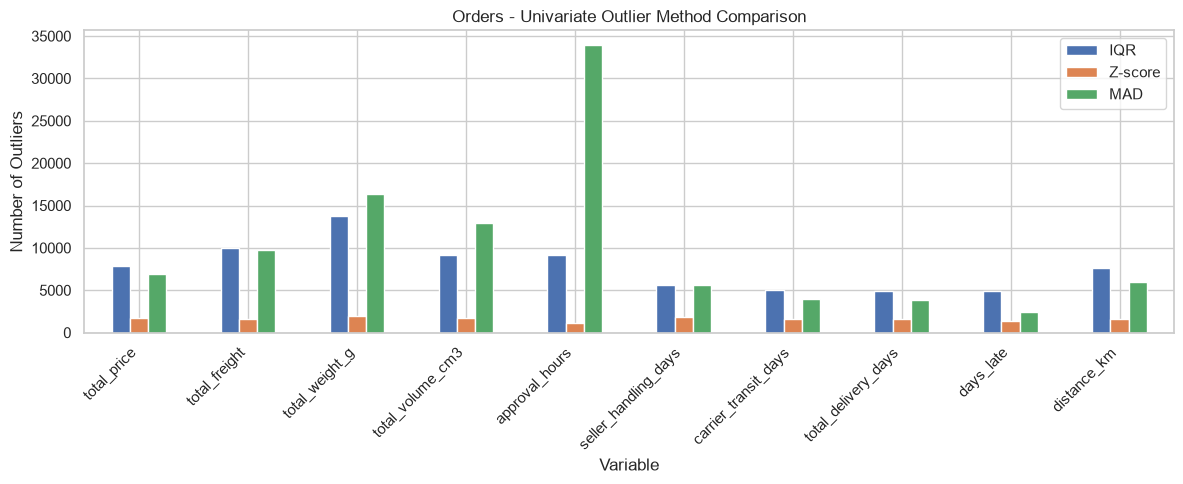

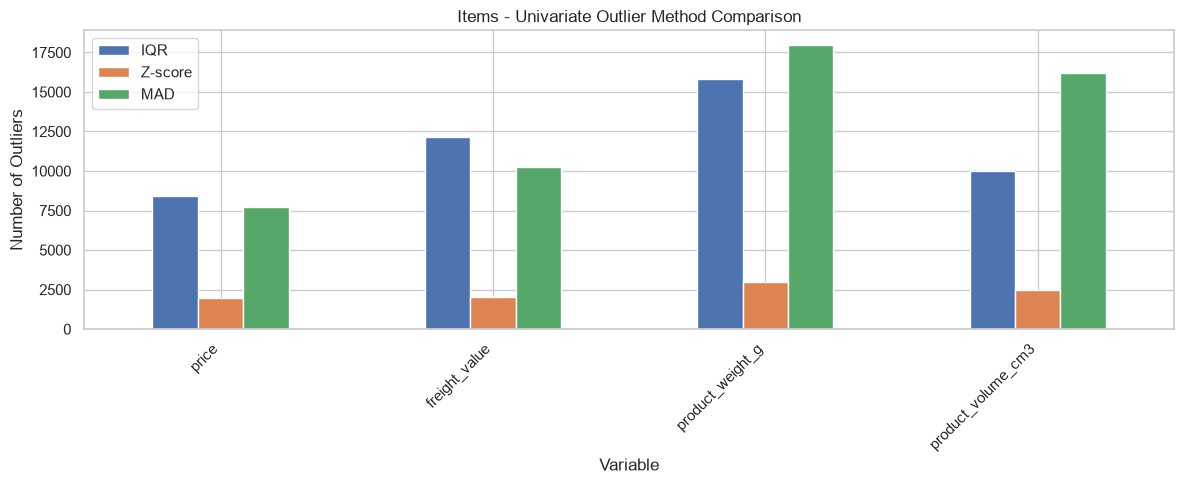

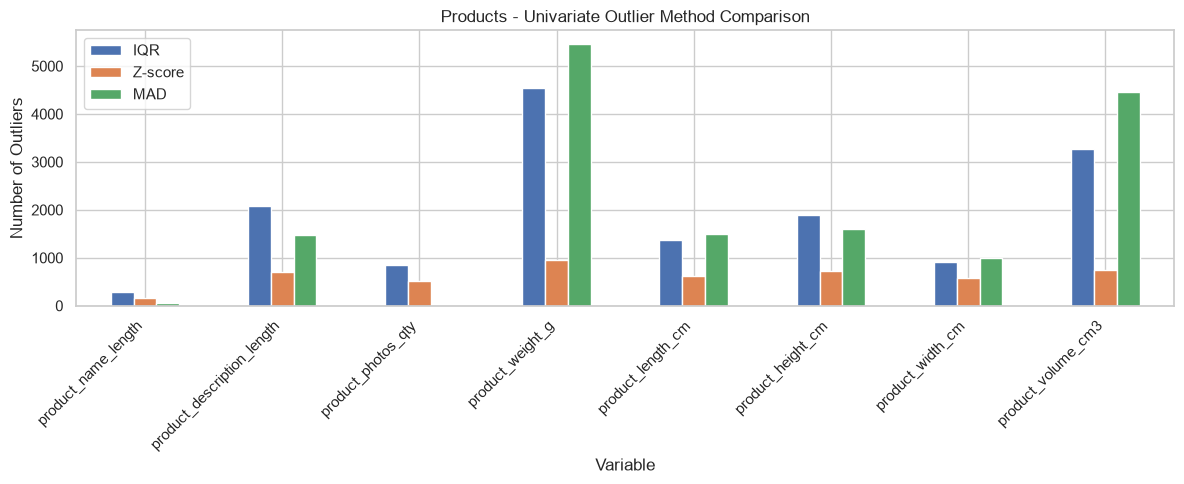

In [17]:
# Plot comparison of univariate outlier counts
for dataset_name in outlier_datasets:
    plot_data = univariate_comparison[
        univariate_comparison["Dataset"] == dataset_name
    ].set_index("Variable")[["IQR", "Z-score", "MAD"]]

    plot_data.plot(kind="bar", figsize=(12, 5))
    plt.title(f"{dataset_name} - Univariate Outlier Method Comparison")
    plt.ylabel("Number of Outliers")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 2.7 Prepare Data for Multivariate Outlier Detection

Isolation Forest, LOF and Mahalanobis Distance examine multiple variables together. For the order-level analysis, selected delivery and transaction variables are used.

The selected columns are converted to numeric values, rows with missing values are excluded for this multivariate experiment, and features are standardized. A reproducible sample is used for LOF and the other multivariate comparisons to keep computation practical.

In [18]:
multivariate_candidates = [
    "total_price", "total_freight", "total_weight_g",
    "total_volume_cm3", "approval_hours",
    "seller_handling_days", "carrier_transit_days",
    "total_delivery_days", "days_late", "distance_km"
]

multivariate_columns = [
    c for c in multivariate_candidates
    if c in master_orders.columns
]

multivariate_data = master_orders[multivariate_columns].apply(
    pd.to_numeric, errors="coerce"
).replace([np.inf, -np.inf], np.nan).dropna()

# Remove constant columns because they do not contribute to distance calculations
multivariate_data = multivariate_data.loc[
    :, multivariate_data.nunique() > 1
]

# Use a reproducible sample to make LOF practical
sample_size = min(10000, len(multivariate_data))
multivariate_sample = multivariate_data.sample(
    n=sample_size, random_state=42
)

scaler_multi = StandardScaler()
X_scaled = scaler_multi.fit_transform(multivariate_sample)

print("Selected features:", multivariate_sample.columns.tolist())
print("Complete observations available:", len(multivariate_data))
print("Sample used for multivariate detection:", X_scaled.shape)

Selected features: ['total_price', 'total_freight', 'total_weight_g', 'total_volume_cm3', 'approval_hours', 'seller_handling_days', 'carrier_transit_days', 'total_delivery_days', 'days_late', 'distance_km']
Complete observations available: 95982
Sample used for multivariate detection: (10000, 10)


### 2.8 Isolation Forest

Isolation Forest identifies anomalies by randomly selecting features and split points. Anomalies are generally isolated in fewer splits than normal observations.

The `contamination` parameter is set to 0.02 for this experiment. This is an assumed expected outlier proportion used by the algorithm, not a known percentage of incorrect records.

- `1` = Normal observation
- `-1` = Outlier

In [19]:
isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

isolation_prediction = isolation_forest.fit_predict(X_scaled)
isolation_flags = pd.Series(
    isolation_prediction == -1,
    index=multivariate_sample.index,
    name="Isolation Forest"
)

print("Isolation Forest")
print("----------------")
print("Sample observations:", len(isolation_flags))
print("Outliers detected:", int(isolation_flags.sum()))
print("Normal observations:", int((~isolation_flags).sum()))

Isolation Forest
----------------
Sample observations: 10000
Outliers detected: 200
Normal observations: 9800


### 2.9 Local Outlier Factor (LOF)

LOF compares the local density of an observation with the density of its nearest neighbours. An observation may be considered anomalous when its local density is substantially lower than the density of its neighbours.

The number of neighbours is set to 20 and contamination is set to 2% for this experiment.

In [20]:
lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.02
)

lof_prediction = lof_model.fit_predict(X_scaled)
lof_flags = pd.Series(
    lof_prediction == -1,
    index=multivariate_sample.index,
    name="LOF"
)

print("Local Outlier Factor")
print("--------------------")
print("Sample observations:", len(lof_flags))
print("Outliers detected:", int(lof_flags.sum()))
print("Normal observations:", int((~lof_flags).sum()))

Local Outlier Factor
--------------------
Sample observations: 10000
Outliers detected: 200
Normal observations: 9800


### 2.10 Mahalanobis Distance

Mahalanobis Distance measures how far an observation is from the multivariate mean while accounting for correlations between variables.

\[
D^2 = (x - \mu)^T S^{-1}(x - \mu)
\]

where \(\mu\) is the mean vector and \(S\) is the covariance matrix.

The squared distance is compared with a chi-square threshold at the 99.7th percentile. This threshold is a reference under a multivariate normal approximation.

In [21]:
X_array = X_scaled
mean_vector = np.mean(X_array, axis=0)
covariance_matrix = np.cov(X_array, rowvar=False)
covariance_inverse = np.linalg.pinv(covariance_matrix)

difference = X_array - mean_vector

mahalanobis_squared = np.sum(
    (difference @ covariance_inverse) * difference,
    axis=1
)

degrees_freedom = X_array.shape[1]
mahalanobis_threshold = chi2.ppf(0.997, df=degrees_freedom)

mahalanobis_flags = pd.Series(
    mahalanobis_squared > mahalanobis_threshold,
    index=multivariate_sample.index,
    name="Mahalanobis"
)

print("Mahalanobis Distance")
print("--------------------")
print("Threshold:", mahalanobis_threshold)
print("Outliers detected:", int(mahalanobis_flags.sum()))
print("Normal observations:", int((~mahalanobis_flags).sum()))

Mahalanobis Distance
--------------------
Threshold: 26.61078512383076
Outliers detected: 523
Normal observations: 9477


### 2.11 Compare Multivariate Outlier Detection Methods

The three multivariate methods are compared using the same sampled observations. The overlap indicates how many observations are flagged by more than one method.

In [22]:
multivariate_comparison = pd.DataFrame({
    "Isolation Forest": isolation_flags,
    "LOF": lof_flags,
    "Mahalanobis": mahalanobis_flags
})

print("Outlier counts by method:")
display(multivariate_comparison.sum().to_frame("Outlier Count"))

multivariate_comparison["Number of Methods Flagging"] = (
    multivariate_comparison.sum(axis=1)
)

print("Number of sampled observations flagged by 2 or more methods:",
      int((multivariate_comparison["Number of Methods Flagging"] >= 2).sum()))

print("Number of sampled observations flagged by all 3 methods:",
      int((multivariate_comparison["Number of Methods Flagging"] == 3).sum()))

Outlier counts by method:


,Outlier Count
Isolation Forest,200
LOF,200
Mahalanobis,523


Number of sampled observations flagged by 2 or more methods: 235
Number of sampled observations flagged by all 3 methods: 65


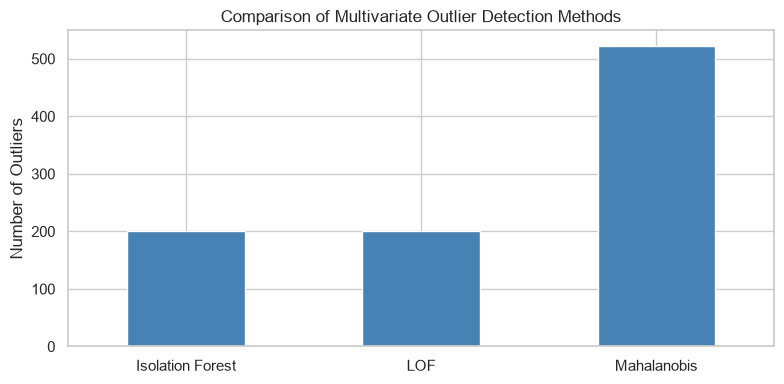

In [23]:
multivariate_comparison[[
    "Isolation Forest", "LOF", "Mahalanobis"
]].sum().plot(kind="bar", figsize=(8, 4), color="steelblue")

plt.title("Comparison of Multivariate Outlier Detection Methods")
plt.ylabel("Number of Outliers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.12 Overall Observations – Outlier Detection

1. **IQR:** Detected a relatively large number of outliers, particularly in product weight (15,807) and total order weight (13,804).

2. **Z-score:** Generally detected fewer outliers than IQR and MAD because it uses the mean and standard deviation.

3. **Modified Z-score (MAD):** Identified more extreme observations in certain variables, such as approval hours (33,961), due to its median-based approach.

4. **Multivariate Methods:** Isolation Forest and LOF detected 200 outliers each, while Mahalanobis Distance detected 523 outliers from the 10,000 sampled orders.

5. **Method Overlap:** 235 observations were flagged by at least two methods, while 65 were identified by all three multivariate methods.

**Conclusion:**

Different outlier detection methods identify different types of unusual observations. Combining statistical and machine learning approaches provides a better understanding of anomalies. However, detected outliers may represent genuine extreme orders and should not be removed without investigation.


## 3. Outlier Handling and Sensitivity Analysis

### Purpose

After detecting outliers, different handling approaches are compared to understand their influence on statistical summaries and distributions.

The following approaches are examined:

1. **Original data:** Retains all observations.
2. **Winsorization:** Caps values below the 1st percentile and above the 99th percentile.
3. **Log transformation:** Applies `log1p` to non-negative variables to reduce right skewness.
4. **Outlier removal:** Removes observations outside the IQR fences for the variable being studied.

The analysis focuses on selected order-level and item-level variables. Outliers are not automatically deleted from the original datasets.

### 3.1 Select Variables for Sensitivity Analysis

The selected variables include order price, freight charges, delivery duration, lateness, distance, product weight and product volume. Negative values are retained in the original and Winsorized data; log transformation is applied only to non-negative variables.

In [25]:
sensitivity_candidates = {
    "Orders": (
        master_orders,
        ["total_price", "total_freight", "total_delivery_days",
         "days_late", "distance_km"]
    ),
    "Items": (
        cleaned_items,
        ["price", "freight_value", "product_weight_g",
         "product_volume_cm3"]
    )
}

sensitivity_data = {}

for name, (data, candidates) in sensitivity_candidates.items():
    columns = [c for c in candidates if c in data.columns]
    sensitivity_data[name] = data[columns].apply(
        pd.to_numeric, errors="coerce"
    )

for name, data in sensitivity_data.items():
    print(name, "selected variables:", data.columns.tolist())

Orders selected variables: ['total_price', 'total_freight', 'total_delivery_days', 'days_late', 'distance_km']
Items selected variables: ['price', 'freight_value', 'product_weight_g', 'product_volume_cm3']


### 3.2 Winsorization (1st and 99th Percentiles)

Winsorization caps extreme observations instead of deleting them. Values below the 1st percentile are replaced with the 1st percentile, and values above the 99th percentile are replaced with the 99th percentile.

In [26]:
winsorized_data = {}

for dataset_name, data in sensitivity_data.items():
    winsorized = data.copy()

    for column in data.columns:
        lower = data[column].quantile(0.01)
        upper = data[column].quantile(0.99)
        winsorized[column] = data[column].clip(
            lower=lower, upper=upper
        )

    winsorized_data[dataset_name] = winsorized

    print("\n", dataset_name, "- Winsorization limits")
    for column in data.columns:
        print(
            column,
            "| 1st percentile:", round(data[column].quantile(0.01), 3),
            "| 99th percentile:", round(data[column].quantile(0.99), 3)
        )


 Orders - Winsorization limits
total_price | 1st percentile: 11.976 | 99th percentile: 998.9
total_freight | 1st percentile: 7.39 | 99th percentile: 104.984
total_delivery_days | 1st percentile: 1.825 | 99th percentile: 46.05
days_late | 1st percentile: -35.154 | 99th percentile: 18.939
distance_km | 1st percentile: 5.745 | 99th percentile: 2482.881

 Items - Winsorization limits
price | 1st percentile: 9.99 | 99th percentile: 890.0
freight_value | 1st percentile: 4.42 | 99th percentile: 84.52
product_weight_g | 1st percentile: 75.0 | 99th percentile: 18250.0
product_volume_cm3 | 1st percentile: 352.0 | 99th percentile: 112284.12


### 3.3 Log Transformation

The `log1p` transformation is:

\[
y = \log(1+x)
\]

It reduces the influence of large positive values. It is applied only when all non-missing observations in a variable are non-negative. Variables such as `days_late` may contain negative values and are therefore not log-transformed in this section.

In [27]:
log_transformed_data = {}

for dataset_name, data in sensitivity_data.items():
    transformed = pd.DataFrame(index=data.index)

    for column in data.columns:
        values = data[column]

        if (values.dropna() >= 0).all():
            transformed[column] = np.log1p(values)
        else:
            transformed[column] = np.nan

    log_transformed_data[dataset_name] = transformed

    print("\n", dataset_name)
    for column in data.columns:
        if transformed[column].notna().any():
            print(
                column,
                "| Original skewness:", round(data[column].skew(), 4),
                "| Log skewness:", round(transformed[column].skew(), 4)
            )
        else:
            print(column, ": log transformation skipped (negative values present).")


 Orders
total_price | Original skewness: 9.7277 | Log skewness: 0.2881
total_freight | Original skewness: 12.0527 | Log skewness: 0.4707
total_delivery_days | Original skewness: 3.8328 | Log skewness: 0.0353
days_late : log transformation skipped (negative values present).
distance_km | Original skewness: 1.6533 | Log skewness: -1.0395

 Items
price | Original skewness: 7.9232 | Log skewness: 0.2935
freight_value | Original skewness: 5.6399 | Log skewness: 0.0011
product_weight_g | Original skewness: 3.5987 | Log skewness: 0.4529
product_volume_cm3 | Original skewness: 4.076 | Log skewness: 0.0324


### 3.4 Outlier Removal Using IQR

For sensitivity analysis, outliers are removed one variable at a time. This makes it possible to compare the original distribution of a variable with the distribution after removing observations outside that variable's IQR fences.



In [29]:
iqr_removed_data = {}

for dataset_name, data in sensitivity_data.items():
    removed_dataset = {}

    for column in data.columns:
        values = data[column].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr_value = q3 - q1

        lower = q1 - 1.5 * iqr_value
        upper = q3 + 1.5 * iqr_value

        filtered_values = values[
            (values >= lower) & (values <= upper)
        ]

        removed_dataset[column] = filtered_values

    iqr_removed_data[dataset_name] = removed_dataset

    print("\n", dataset_name, "- IQR Removal")
    for column, filtered_values in removed_dataset.items():
        original_count = data[column].notna().sum()
        removed_count = original_count - len(filtered_values)
        print(
            column,
            "| Original:", original_count,
            "| Remaining:", len(filtered_values),
            "| Removed:", removed_count
        )


 Orders - IQR Removal
total_price | Original: 98666 | Remaining: 90753 | Removed: 7913
total_freight | Original: 98666 | Remaining: 88725 | Removed: 9941
total_delivery_days | Original: 96476 | Remaining: 91577 | Removed: 4899
days_late | Original: 96476 | Remaining: 91601 | Removed: 4875
distance_km | Original: 98174 | Remaining: 90552 | Removed: 7622

 Items - IQR Removal
price | Original: 112650 | Remaining: 104223 | Removed: 8427
freight_value | Original: 112650 | Remaining: 100516 | Removed: 12134
product_weight_g | Original: 112632 | Remaining: 96825 | Removed: 15807
product_volume_cm3 | Original: 112632 | Remaining: 102628 | Removed: 10004


### 3.5 Compare Statistical Summaries Before and After Handling

Mean, median, standard deviation and skewness are compared to understand how each treatment changes the distribution. The comparison is performed separately for each variable.

In [30]:
sensitivity_results = []

for dataset_name, data in sensitivity_data.items():
    for column in data.columns:
        original_values = data[column].dropna()
        winsor_values = winsorized_data[dataset_name][column].dropna()
        log_values = log_transformed_data[dataset_name][column].dropna()
        removed_values = iqr_removed_data[dataset_name][column]

        comparison_sets = {
            "Original": original_values,
            "Winsorized": winsor_values,
            "Log Transformed": log_values,
            "IQR Outliers Removed": removed_values
        }

        for method, values in comparison_sets.items():
            sensitivity_results.append({
                "Dataset": dataset_name,
                "Variable": column,
                "Method": method,
                "Count": len(values),
                "Mean": values.mean(),
                "Median": values.median(),
                "Standard Deviation": values.std(),
                "Skewness": values.skew()
            })

sensitivity_summary = pd.DataFrame(sensitivity_results)
display(sensitivity_summary.round(4))

,Dataset,Variable,Method,Count,Mean,Median,Standard Deviation,Skewness
0,Orders,total_price,Original,98666,137.7541,86.9000,210.6451,9.7277
1,Orders,total_price,Winsorized,98666,131.8215,86.9000,155.9535,3.2761
2,Orders,total_price,Log Transformed,98666,4.4610,4.4762,0.9187,0.2881
3,Orders,total_price,IQR Outliers Removed,90753,94.4392,79.0000,66.0580,1.0347
4,Orders,total_freight,Original,98666,22.8236,17.1700,21.6509,12.0527
5,Orders,total_freight,Winsorized,98666,22.2846,17.1700,16.3084,2.7465
6,Orders,total_freight,Log Transformed,98666,2.9876,2.8998,0.5567,0.4707
7,Orders,total_freight,IQR Outliers Removed,88725,17.7864,16.3400,7.1577,0.9184
8,Orders,total_delivery_days,Original,96476,12.5587,10.2178,9.5465,3.8328
9,Orders,total_delivery_days,Winsorized,96476,12.3968,10.2178,8.4078,1.6235


### 3.6 Visual Comparison of Original and Winsorized Distributions

The histograms below compare the original and Winsorized distributions. Winsorization retains the number of observations but caps extreme values at the selected percentile limits.

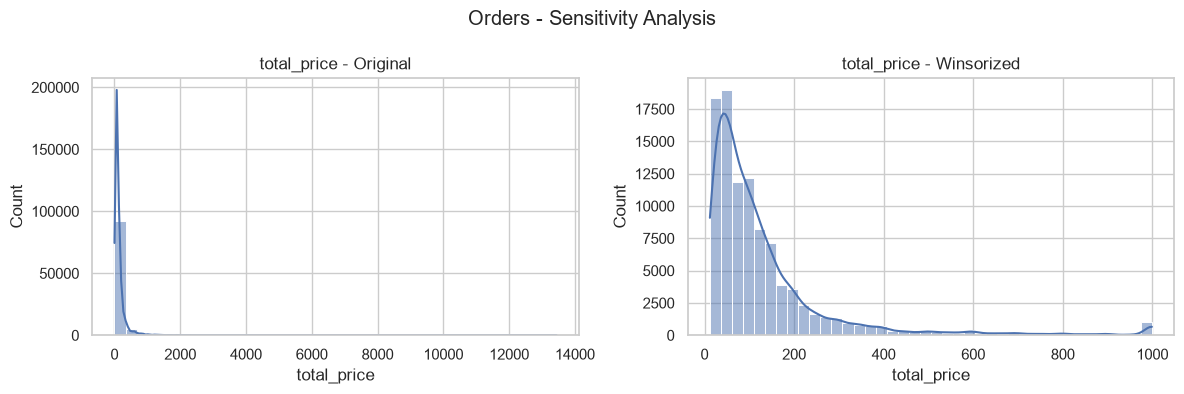

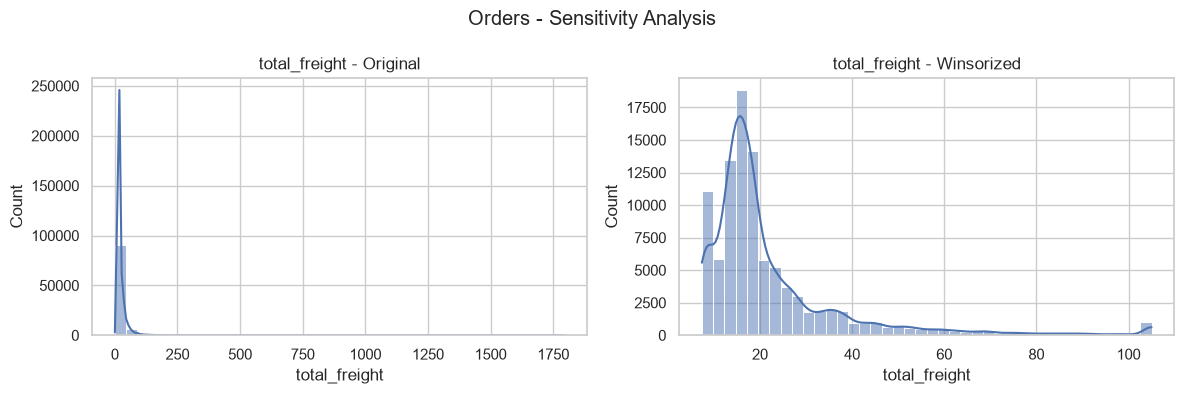

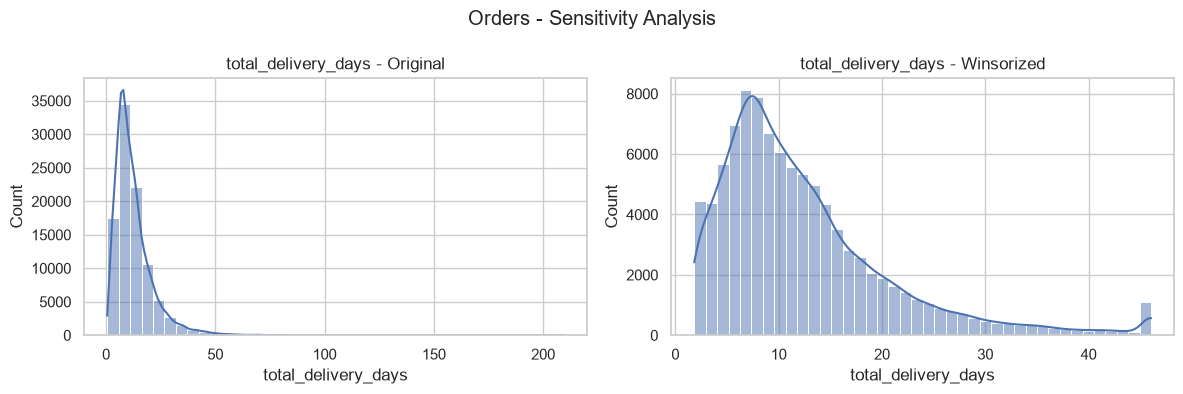

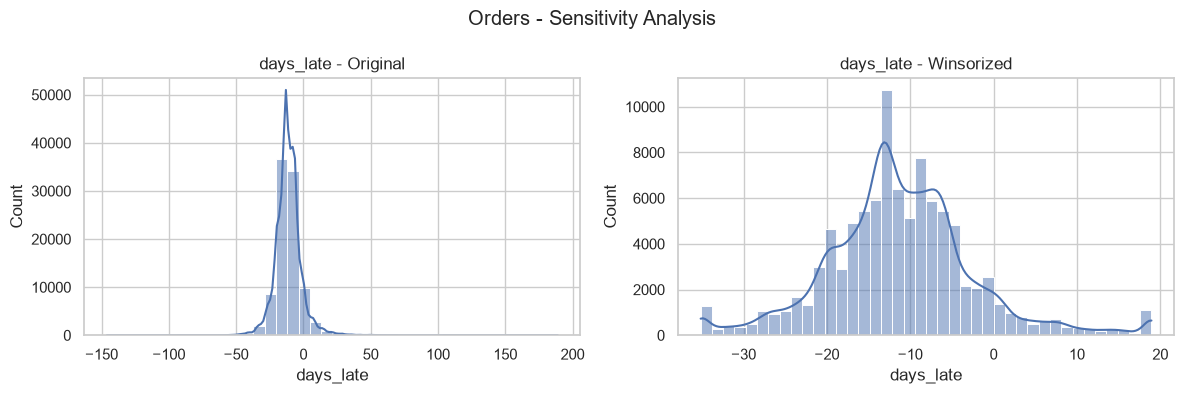

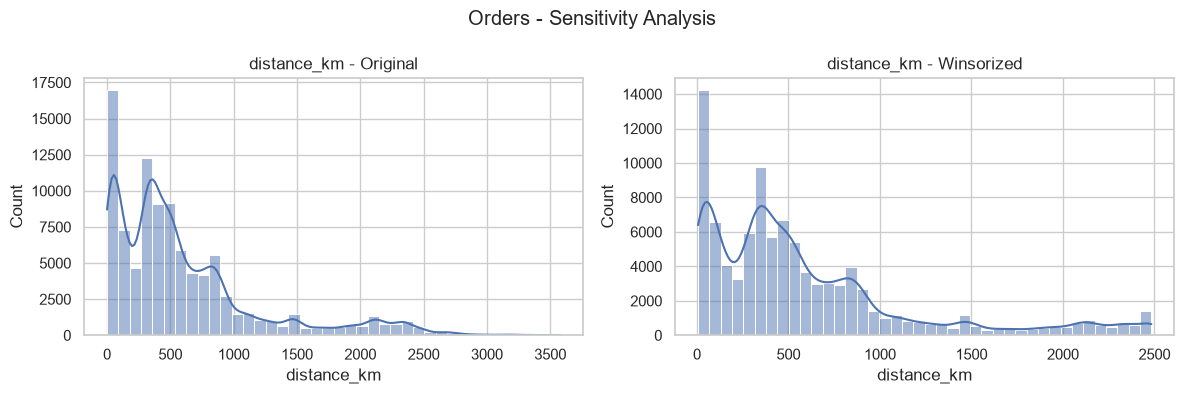

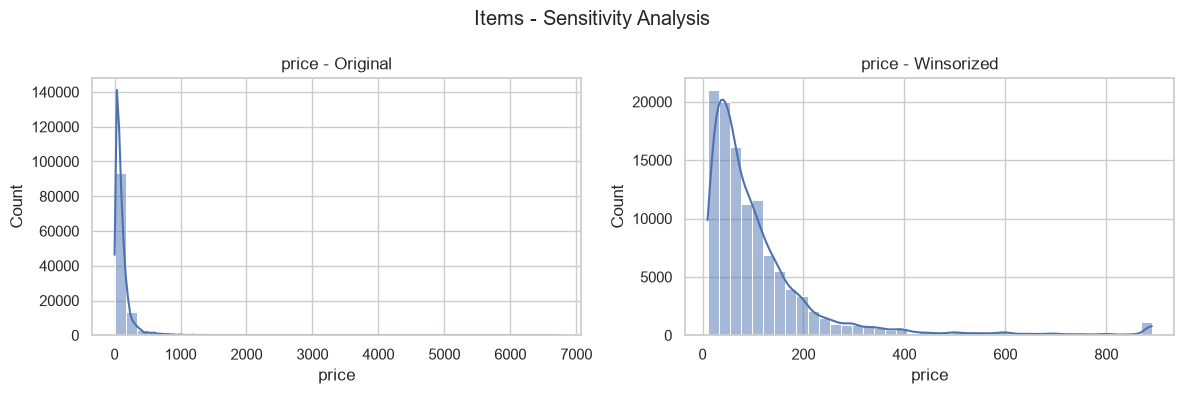

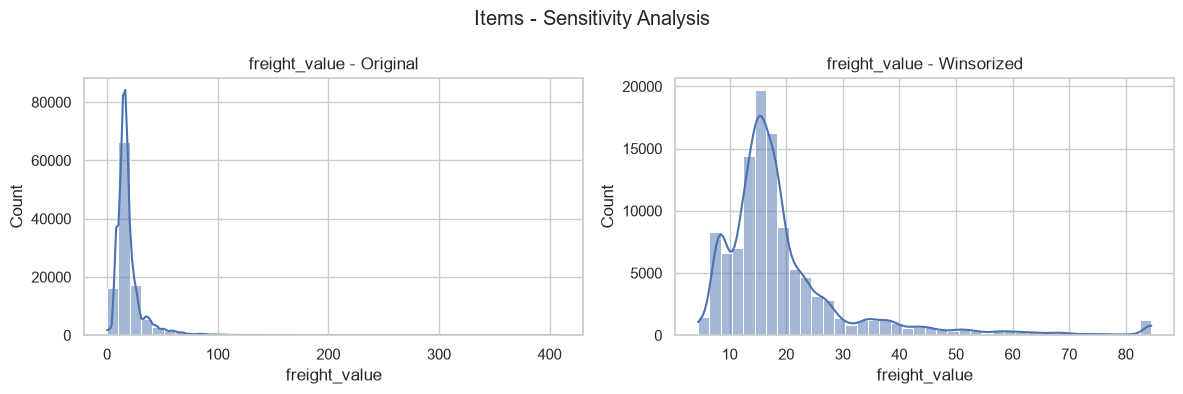

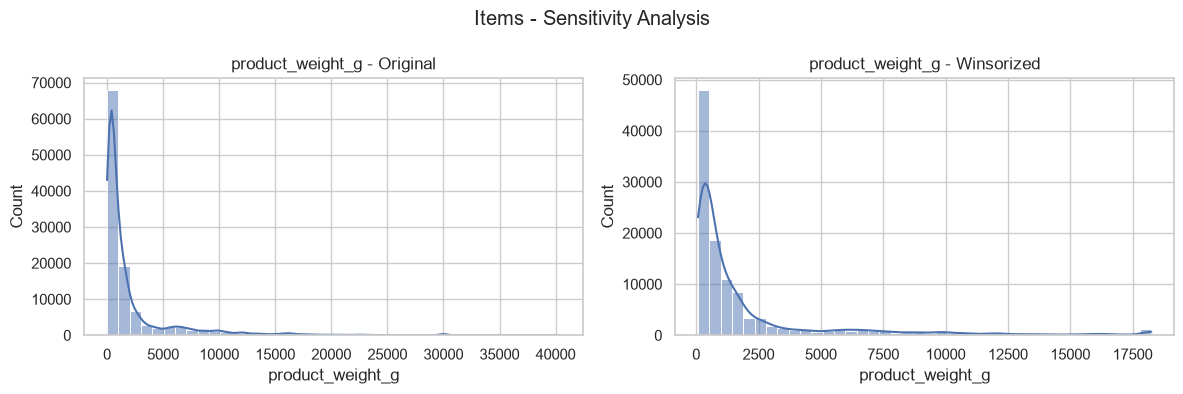

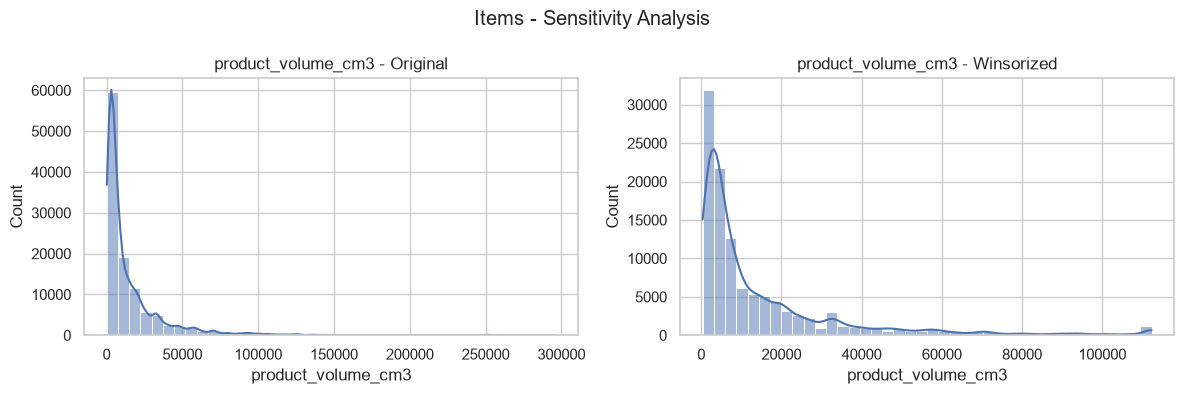

In [31]:
for dataset_name, data in sensitivity_data.items():
    for column in data.columns:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        sns.histplot(
            data[column].dropna(), bins=40, kde=True, ax=axes[0]
        )
        axes[0].set_title(f"{column} - Original")

        sns.histplot(
            winsorized_data[dataset_name][column].dropna(),
            bins=40, kde=True, ax=axes[1]
        )
        axes[1].set_title(f"{column} - Winsorized")

        fig.suptitle(f"{dataset_name} - Sensitivity Analysis")
        plt.tight_layout()
        plt.show()

### 3.7 Observations – Outlier Handling and Sensitivity Analysis

1. **Winsorization:** Capping values at the 1st and 99th percentiles reduced the standard deviation across all selected variables while retaining the original number of observations.

2. **Mean and Median:** The mean decreased after Winsorization, whereas the median remained unchanged. This shows that the mean is more sensitive to extreme values.

3. **Log Transformation:** Log transformation significantly reduced positive skewness. For example, total freight skewness decreased from 12.0527 to 0.4707, making the distribution more symmetric.

4. **IQR-Based Removal:** Product weight had the highest number of outliers removed (15,807), followed by freight value (12,134).

5. **Overall Comparison:** Winsorization reduced the influence of extreme values, log transformation reduced skewness, and IQR removal excluded extreme observations.

**Conclusion:**

Different outlier-handling techniques affect the statistical properties of the dataset differently. Genuine extreme observations may represent important business information, so they should not be removed without investigation. The appropriate method should be selected based on the analysis objective.

## 4. Missing Value Analysis

### Purpose

Missing values occur when a feature has no recorded value. Missing product dimensions or weights may affect freight analysis and later machine learning models.

This section identifies missing values in the processed datasets and studies whether missing review comments are associated with customer ratings and delivery lateness.

### 4.1 Missing Value Count and Percentage

For each dataset, the number and percentage of missing values are calculated column by column.

In [32]:
missing_tables = {}

for dataset_name, data in datasets.items():
    missing_table = pd.DataFrame({
        "Missing Count": data.isnull().sum(),
        "Missing Percentage": data.isnull().mean() * 100
    }).sort_values("Missing Percentage", ascending=False)

    missing_tables[dataset_name] = missing_table

    print("\n", dataset_name.upper(), "- Missing Value Summary")
    display(missing_table[missing_table["Missing Count"] > 0].round(2))


 MASTER_ORDERS - Missing Value Summary


,Missing Count,Missing Percentage
review_comment_title,87890,88.38
review_comment_message,58664,58.99
carrier_transit_days,2966,2.98
total_delivery_days,2965,2.98
lateness_bucket,2965,2.98
is_late,2965,2.98
days_late,2965,2.98
order_delivered_customer_date,2965,2.98
seller_handling_days,1797,1.81
order_delivered_carrier_date,1783,1.79



 MASTER_SELLERS - Missing Value Summary


,Missing Count,Missing Percentage
avg_transit_days,125,4.04
late_rate,125,4.04
avg_days_late,125,4.04
avg_delivery_days,125,4.04
median_handling_days,118,3.81
avg_handling_days,118,3.81
avg_distance_km,5,0.16
avg_review_score,5,0.16
low_review_rate,5,0.16



 CLEANED_PRODUCTS - Missing Value Summary


,Missing Count,Missing Percentage
product_category_name,610,1.85
product_name_length,610,1.85
product_description_length,610,1.85
product_photos_qty,610,1.85
product_height_cm,2,0.01
product_weight_g,2,0.01
product_length_cm,2,0.01
product_volume_cm3,2,0.01
product_width_cm,2,0.01



 CLEANED_ITEMS - Missing Value Summary


,Missing Count,Missing Percentage
product_volume_cm3,18,0.02
product_weight_g,18,0.02



 CLEANED_REVIEWS - Missing Value Summary


,Missing Count,Missing Percentage
review_comment_title,87122,88.29
review_comment_message,57896,58.67


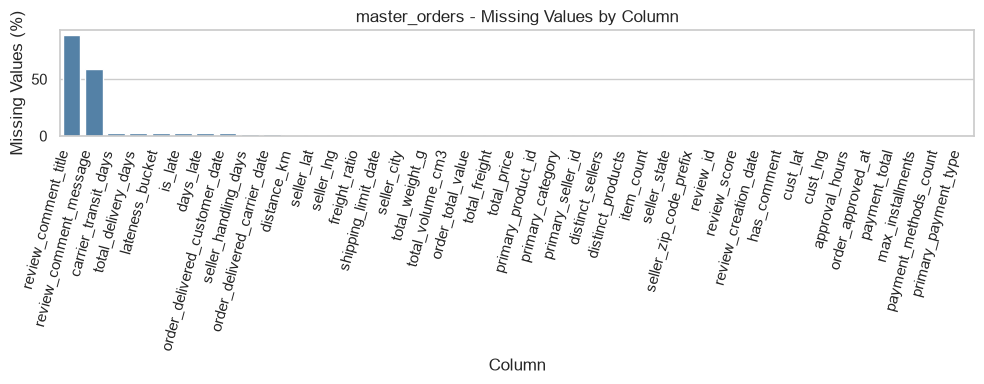

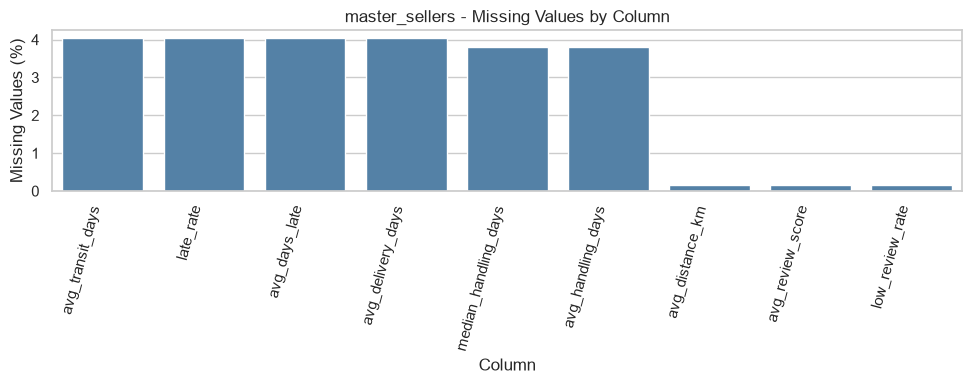

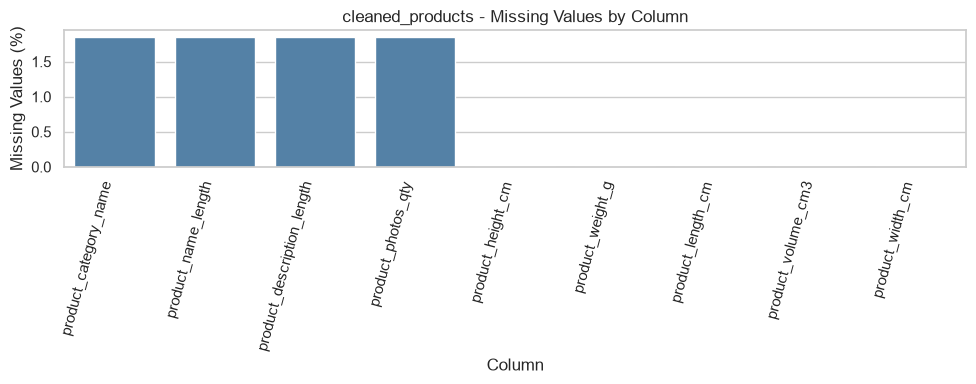

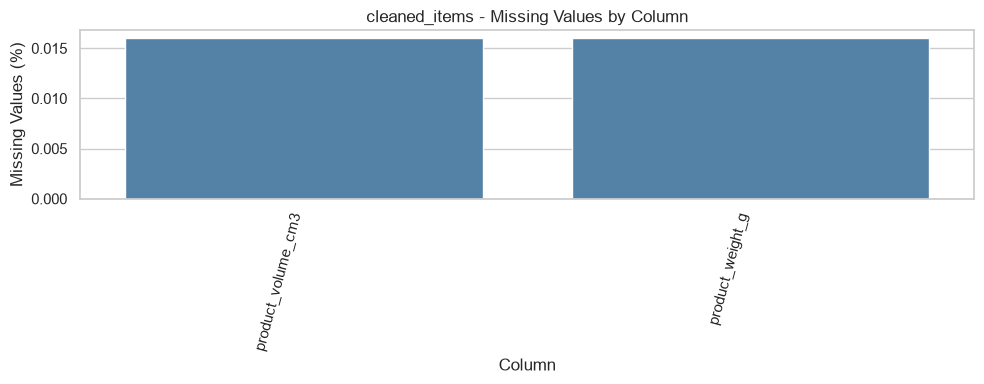

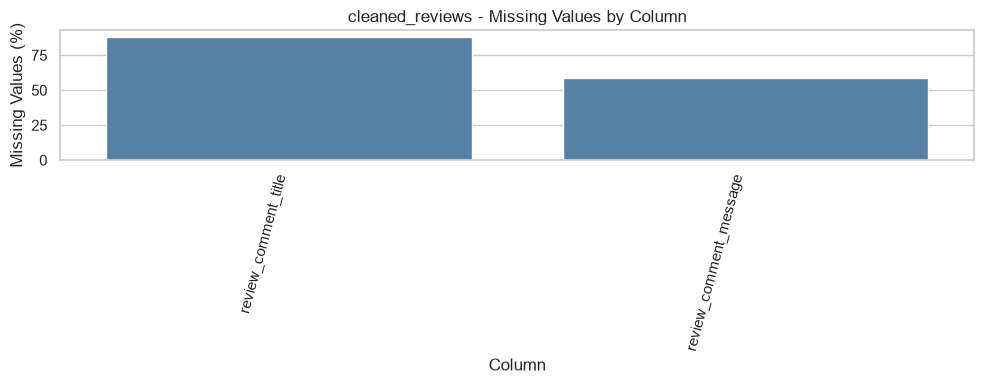

In [33]:
# Visualize missing-value percentages for each dataset
for dataset_name, missing_table in missing_tables.items():
    plot_table = missing_table[
        missing_table["Missing Percentage"] > 0
    ].sort_values("Missing Percentage", ascending=False)

    if len(plot_table) > 0:
        plt.figure(figsize=(10, 4))
        sns.barplot(
            x=plot_table.index,
            y=plot_table["Missing Percentage"],
            color="steelblue"
        )
        plt.title(f"{dataset_name} - Missing Values by Column")
        plt.ylabel("Missing Values (%)")
        plt.xlabel("Column")
        plt.xticks(rotation=75, ha="right")
        plt.tight_layout()
        plt.show()

### 4.2 Missing Review Comment Analysis

The review dataset contains review scores and written comments. A missing comment does not mean that the review score itself is missing.

A binary variable is used:

- `1` = A written comment is available.
- `0` = No written comment is available.

The analysis examines comment availability by review score and by delivery lateness category

In [34]:

review_analysis = master_orders[
    ["order_id", "review_score", "days_late", "has_comment"]
].copy()


if "has_comment" not in review_analysis.columns:
    review_analysis["has_comment"] = (
        master_orders["review_comment_message"].notna().astype(int)
    )

review_analysis["has_comment"] = pd.to_numeric(
    review_analysis["has_comment"], errors="coerce"
)

review_analysis = review_analysis.dropna(
    subset=["review_score", "days_late", "has_comment"]
)

review_analysis["has_comment"] = (
    review_analysis["has_comment"] > 0
).astype(int)

print("Review analysis shape:", review_analysis.shape)
display(review_analysis.head())
print("\nComment availability:")
display(review_analysis["has_comment"].value_counts())

Review analysis shape: (95830, 4)


,order_id,review_score,days_late,has_comment
0,e481f51cbdc54678b7cc49136f2d6af7,4.0,-7.107488,1
1,53cdb2fc8bc7dce0b6741e2150273451,4.0,-5.355729,1
2,47770eb9100c2d0c44946d9cf07ec65d,5.0,-17.245498,0
3,949d5b44dbf5de918fe9c16f97b45f8a,5.0,-12.980069,1
4,ad21c59c0840e6cb83a9ceb5573f8159,5.0,-9.238171,0



Comment availability:


has_comment
0    56924
1    38906
Name: count, dtype: int64

### 4.3 Comment Availability by Review Score

The percentage of customers who wrote comments is calculated for each review score. This helps determine whether customers giving lower ratings are more likely to explain their experience in writing.

Comment Availability by Review Score


,count,mean,Comment Percentage
review_score,,,
1.0,9355,0.78,77.56
2.0,2919,0.68,67.87
3.0,7917,0.43,43.34
4.0,18895,0.31,31.19
5.0,56744,0.36,35.85


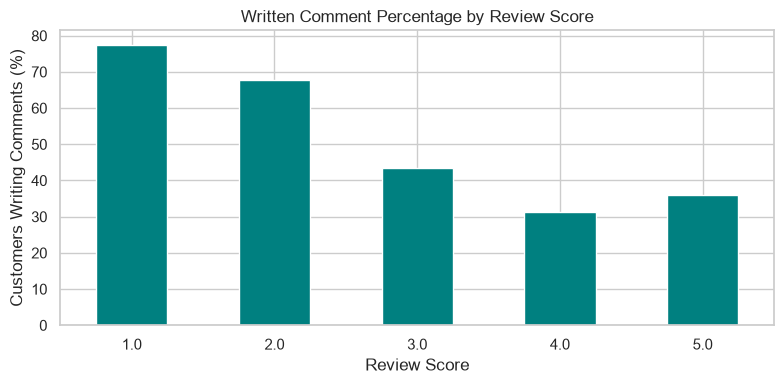

In [35]:
comment_by_score = (
    review_analysis.groupby("review_score")["has_comment"]
    .agg(["count", "mean"])
)

comment_by_score["Comment Percentage"] = (
    comment_by_score["mean"] * 100
)

print("Comment Availability by Review Score")
display(comment_by_score.round(2))

comment_by_score["Comment Percentage"].plot(
    kind="bar", figsize=(8, 4), color="teal"
)
plt.title("Written Comment Percentage by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Customers Writing Comments (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.4 Comment Availability by Delivery Lateness

Orders are grouped into five lateness categories: Early, On Time, 1–3 Days Late, 4–7 Days Late and more than 7 Days Late. The percentage of orders with written comments is compared across these groups.

,count,mean,Comment Percentage
lateness_bucket,,,
Early,86718,0.39,39.34
On Time,1450,0.37,36.62
1-3 Days Late,2636,0.42,42.07
4-7 Days Late,1773,0.58,57.70
>7 Days Late,3253,0.65,65.36


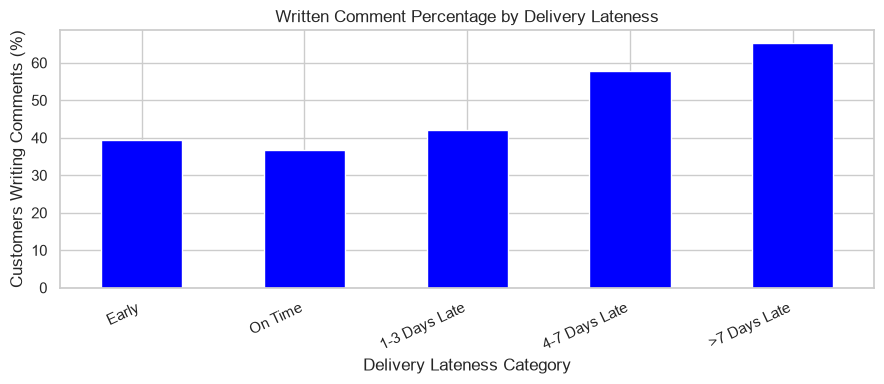

In [37]:
def make_lateness_bucket(days):
    if pd.isna(days):
        return np.nan
    elif days < -1:
        return "Early"
    elif days <= 0:
        return "On Time"
    elif days <= 3:
        return "1-3 Days Late"
    elif days <= 7:
        return "4-7 Days Late"
    else:
        return ">7 Days Late"

lateness_order = [
    "Early", "On Time", "1-3 Days Late",
    "4-7 Days Late", ">7 Days Late"
]

review_analysis["lateness_bucket"] = (
    review_analysis["days_late"].apply(make_lateness_bucket)
)

comment_by_lateness = (
    review_analysis.groupby("lateness_bucket", observed=False)["has_comment"]
    .agg(["count", "mean"])
    .reindex(lateness_order)
)

comment_by_lateness["Comment Percentage"] = (
    comment_by_lateness["mean"] * 100
)

display(comment_by_lateness.round(2))

comment_by_lateness["Comment Percentage"].plot(
    kind="bar", figsize=(9, 4), color="blue"
)
plt.title("Written Comment Percentage by Delivery Lateness")
plt.xlabel("Delivery Lateness Category")
plt.ylabel("Customers Writing Comments (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 4.5 Chi-Square Test: Comment Availability and Delivery Lateness

The Chi-Square Test of Independence checks whether written-comment availability is associated with delivery lateness category.

**Hypotheses**

- **H0:** Comment availability and delivery lateness category are independent.
- **H1:** Comment availability and delivery lateness category are associated.

A significance level of 0.05 is used.

In [38]:
comment_contingency = pd.crosstab(
    review_analysis["lateness_bucket"],
    review_analysis["has_comment"]
).reindex(lateness_order).fillna(0)

comment_contingency.columns = [
    "No Comment" if c == 0 else "Has Comment"
    for c in comment_contingency.columns
]

print("CONTINGENCY TABLE")
display(comment_contingency)

chi2_comment, p_comment, dof_comment, expected_comment = (
    chi2_contingency(comment_contingency)
)

print("\nCHI-SQUARE TEST")
print("----------------")
print("Chi-square statistic:", chi2_comment)
print("Degrees of freedom:", dof_comment)
print("P-value:", p_comment)

if p_comment < 0.05:
    print("Result: Reject H0. Comment availability is significantly associated with delivery lateness category.")
else:
    print("Result: Fail to reject H0. No statistically significant association was found.")

CONTINGENCY TABLE


,No Comment,Has Comment
lateness_bucket,,
Early,52601,34117
On Time,919,531
1-3 Days Late,1527,1109
4-7 Days Late,750,1023
>7 Days Late,1127,2126



CHI-SQUARE TEST
----------------
Chi-square statistic: 1110.3127192541285
Degrees of freedom: 4
P-value: 4.404061025408941e-239
Result: Reject H0. Comment availability is significantly associated with delivery lateness category.


### 4.6 Logistic Regression: Predicting Comment Availability

Logistic Regression is used to examine whether review score and delivery lateness contain information useful for predicting whether a customer wrote a comment.

**Target variable:** `has_comment` (1 = comment available, 0 = no comment)

**Predictor variables:** `review_score` and `days_late`

A train-test split is used. Missing predictor values are imputed using the training pipeline, and numerical features are standardized.

In [39]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

X = review_analysis[["review_score", "days_late"]]
y = review_analysis["has_comment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

comment_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

comment_model.fit(X_train, y_train)
y_pred_comment = comment_model.predict(X_test)

print("LOGISTIC REGRESSION - COMMENT AVAILABILITY")
print("------------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_comment), 4))
print("Precision:", round(precision_score(y_test, y_pred_comment, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_comment, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_comment, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_comment, zero_division=0))

print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred_comment),
    index=["Actual No Comment", "Actual Has Comment"],
    columns=["Predicted No Comment", "Predicted Has Comment"]
))

LOGISTIC REGRESSION - COMMENT AVAILABILITY
------------------------------------------
Accuracy: 0.58
Precision: 0.4821
Recall: 0.4651
F1-score: 0.4735

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.66      0.65     11385
           1       0.48      0.47      0.47      7781

    accuracy                           0.58     19166
   macro avg       0.56      0.56      0.56     19166
weighted avg       0.58      0.58      0.58     19166

Confusion Matrix:


,Predicted No Comment,Predicted Has Comment
Actual No Comment,7498,3887
Actual Has Comment,4162,3619



### 4.7 Observations – Missing Review Comments

1. **Review Score:** Customers giving 1-star ratings had the highest comment-writing percentage (77.56%), while 4-star reviewers had the lowest (31.19%).

2. **Delivery Lateness:** Comment-writing percentage was highest for orders delayed by more than 7 days (65.36%), compared with 36.62% for on-time orders.

3. **Chi-Square Test:** The p-value was 4.4041 × 10⁻²³⁹, which is below 0.05. Therefore, comment availability is significantly associated with delivery lateness.

4. **Logistic Regression:** The model achieved 58% accuracy and an F1-score of 0.4735, indicating limited predictive performance using review score and delivery lateness alone.

**Conclusion:**

Unhappy customers and customers experiencing longer delivery delays are more likely to provide written comments. However, Logistic Regression shows that review score and lateness alone are not sufficient to predict comment availability accurately.

## 5. Missing Value Imputation Experiment

### Purpose

The project compares four methods for imputing missing product weight and dimensions:

1. **Mean Imputation:** Replaces missing values with the mean of the feature.
2. **Category Median Imputation:** Replaces missing values using the median for the corresponding product category.
3. **KNN Imputation:** Estimates missing values using similar product observations.
4. **Iterative Imputation (MICE):** Repeatedly predicts missing features using the other available features.

### Why a Masking Experiment is Required

For naturally missing values, the true value is unknown, so the imputation error cannot be calculated directly.

To compare methods fairly, 15% of known values are artificially hidden. The imputation methods estimate these hidden values, and their predictions are compared with the original values.

The evaluation metrics are:

\[
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|
\]

\[
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}
\]

Lower MAE and RMSE indicate more accurate imputation for the masked observations.

### 5.1 Select Product Features

The experiment uses product weight, length, height and width. The English product category is used for category-based median imputation; if it is unavailable, the original Portuguese category column is used.

In [40]:
imputation_features = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

imputation_features = [
    c for c in imputation_features
    if c in cleaned_products.columns
]

category_column = (
    "product_category_name_english"
    if "product_category_name_english" in cleaned_products.columns
    else "product_category_name"
)

if category_column not in cleaned_products.columns:
    raise ValueError("No product category column was found in cleaned_products.")

product_imputation_data = cleaned_products[
    imputation_features
].apply(pd.to_numeric, errors="coerce")

product_categories = cleaned_products[category_column].fillna(
    "Unknown"
).astype(str)

print("Features used:", imputation_features)
print("Category column:", category_column)
print("Product data shape:", product_imputation_data.shape)

print("\nMissing values before masking:")
display(product_imputation_data.isnull().sum().to_frame("Missing Count"))

display(product_imputation_data.head())

Features used: ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
Category column: product_category_name_english
Product data shape: (32951, 4)

Missing values before masking:


,Missing Count
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.2 Artificially Mask 15% of Known Values

For each selected feature, 15% of its known observations are randomly selected and replaced with missing values. The original values are saved separately for evaluation.

A fixed random seed is used so that the experiment can be reproduced.

In [41]:
np.random.seed(42)

X_original = product_imputation_data.copy()
X_masked = X_original.copy()

actual_masked_values = {}
masked_indices = {}

for column in imputation_features:
    known_indices = X_original[column].dropna().index

    number_to_mask = int(0.15 * len(known_indices))

    selected_indices = np.random.choice(
        known_indices,
        size=number_to_mask,
        replace=False
    )

    masked_indices[column] = selected_indices
    actual_masked_values[column] = X_original.loc[
        selected_indices, column
    ].copy()

    X_masked.loc[selected_indices, column] = np.nan

print("Missing values before artificial masking:")
display(X_original.isnull().sum().to_frame("Missing Count"))

print("\nMissing values after artificial masking:")
display(X_masked.isnull().sum().to_frame("Missing Count"))

print("\nNumber of artificially hidden values:")
for column in imputation_features:
    print(column, ":", len(masked_indices[column]))

Missing values before artificial masking:


,Missing Count
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



Missing values after artificial masking:


,Missing Count
product_weight_g,4944
product_length_cm,4944
product_height_cm,4944
product_width_cm,4944



Number of artificially hidden values:
product_weight_g : 4942
product_length_cm : 4942
product_height_cm : 4942
product_width_cm : 4942


### 5.3 Mean Imputation

In [43]:
mean_imputer = SimpleImputer(strategy="mean")

mean_array = mean_imputer.fit_transform(X_masked)

mean_imputed = pd.DataFrame(
    mean_array,
    columns=imputation_features,
    index=X_masked.index
)

print("Mean Imputation - Remaining Missing Values")
display(mean_imputed.isnull().sum().to_frame("Missing Count"))

display(mean_imputed.head())

Mean Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.4 Category Median Imputation

Category Median Imputation replaces a missing product measurement with the median measurement of products belonging to the same category.

If a category has no available values for a particular feature, the overall median of that feature is used as a fallback.

In [45]:
category_median_imputed = X_masked.copy()

for column in imputation_features:
    temporary_data = pd.DataFrame({
        "category": product_categories,
        "value": X_masked[column]
    })

    category_medians = temporary_data.groupby(
        "category"
    )["value"].transform("median")

    category_median_imputed[column] = (
        category_median_imputed[column]
        .fillna(category_medians)
    )

    # Fallback for categories with no available median
    category_median_imputed[column] = (
        category_median_imputed[column]
        .fillna(X_original[column].median())
    )

print("Category Median Imputation - Remaining Missing Values")
display(category_median_imputed.isnull().sum().to_frame("Missing Count"))

display(category_median_imputed.head())

Category Median Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.5 KNN Imputation

KNN Imputation estimates missing values using nearby observations. Since the selected features have different units and ranges (grams and centimetres), the features are scaled before applying KNN.

After imputation, the values are converted back to their original units.

In [46]:
# Scale features before KNN so that large-unit variables do not dominate distances.
knn_scaler = MinMaxScaler()
X_masked_scaled = knn_scaler.fit_transform(X_masked)

knn_imputer = KNNImputer(n_neighbors=5)

knn_imputed_scaled = knn_imputer.fit_transform(X_masked_scaled)

knn_imputed_array = knn_scaler.inverse_transform(
    knn_imputed_scaled
)

knn_imputed = pd.DataFrame(
    knn_imputed_array,
    columns=imputation_features,
    index=X_masked.index
)

print("KNN Imputation - Remaining Missing Values")
display(knn_imputed.isnull().sum().to_frame("Missing Count"))

display(knn_imputed.head())

KNN Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.6 Iterative Imputation (MICE)

Iterative Imputation estimates each feature with missing values using the other features as predictors. The process is repeated for multiple iterations until the estimates stabilize or the maximum number of iterations is reached.

Features are scaled before the iterative procedure because they have different units and ranges. The imputed values are then converted back to their original units.

In [47]:
iterative_scaler = MinMaxScaler()
X_masked_scaled_for_mice = iterative_scaler.fit_transform(X_masked)

iterative_imputer = IterativeImputer(
    max_iter=10,
    random_state=42,
    initial_strategy="median"
)

iterative_imputed_scaled = iterative_imputer.fit_transform(
    X_masked_scaled_for_mice
)

iterative_imputed_array = iterative_scaler.inverse_transform(
    iterative_imputed_scaled
)

iterative_imputed = pd.DataFrame(
    iterative_imputed_array,
    columns=imputation_features,
    index=X_masked.index
)

print("Iterative (MICE) Imputation - Remaining Missing Values")
display(iterative_imputed.isnull().sum().to_frame("Missing Count"))

display(iterative_imputed.head())

Iterative (MICE) Imputation - Remaining Missing Values


,Missing Count
product_weight_g,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,225.0,16.0,10.0,14.0
1,1000.0,30.0,18.0,20.0
2,154.0,18.0,9.0,15.0
3,371.0,26.0,4.0,26.0
4,625.0,20.0,17.0,13.0


### 5.7 Compare Imputation Methods Using MAE and RMSE

Only the artificially hidden values are used for evaluation. Naturally missing values are not included in the error calculation because their true values are unknown.

The imputation methods were evaluated using artificially masked values because the actual missing values do not have known ground-truth measurements. The experiment provides a comparative evaluation under simulated missingness.

The four methods are compared separately for each product feature.

In [49]:
imputation_methods = {
    "Mean": mean_imputed,
    "Category Median": category_median_imputed,
    "KNN": knn_imputed,
    "Iterative MICE": iterative_imputed
}

imputation_results = []

for column in imputation_features:
    actual_values = actual_masked_values[column]

    for method_name, imputed_data in imputation_methods.items():
        predicted_values = imputed_data.loc[
            actual_values.index, column
        ]

        mae_value = mean_absolute_error(
            actual_values, predicted_values
        )

        rmse_value = np.sqrt(
            mean_squared_error(actual_values, predicted_values)
        )

        imputation_results.append({
            "Feature": column,
            "Method": method_name,
            "MAE": mae_value,
            "RMSE": rmse_value,
            "Number of Masked Values": len(actual_values)
        })

imputation_results_df = pd.DataFrame(imputation_results)

print("IMPUTATION PERFORMANCE COMPARISON")
display(imputation_results_df.round(4))

IMPUTATION PERFORMANCE COMPARISON


,Feature,Method,MAE,RMSE,Number of Masked Values
0,product_weight_g,Mean,2550.8974,4368.1240,4942
1,product_weight_g,Category Median,1759.9064,4243.9334,4942
2,product_weight_g,KNN,2155.8814,3980.4625,4942
3,product_weight_g,Iterative MICE,1951.2404,3228.1756,4942
4,product_length_cm,Mean,12.6504,16.7733,4942
5,product_length_cm,Category Median,9.9734,15.6071,4942
6,product_length_cm,KNN,11.0048,15.9656,4942
7,product_length_cm,Iterative MICE,9.2082,13.7017,4942
8,product_height_cm,Mean,9.6799,13.8870,4942
9,product_height_cm,Category Median,8.3616,13.2322,4942


### 5.8 Visualize MAE Comparison

The MAE plot compares the average absolute imputation error across the four methods. A lower bar indicates a smaller average prediction error for the masked values.

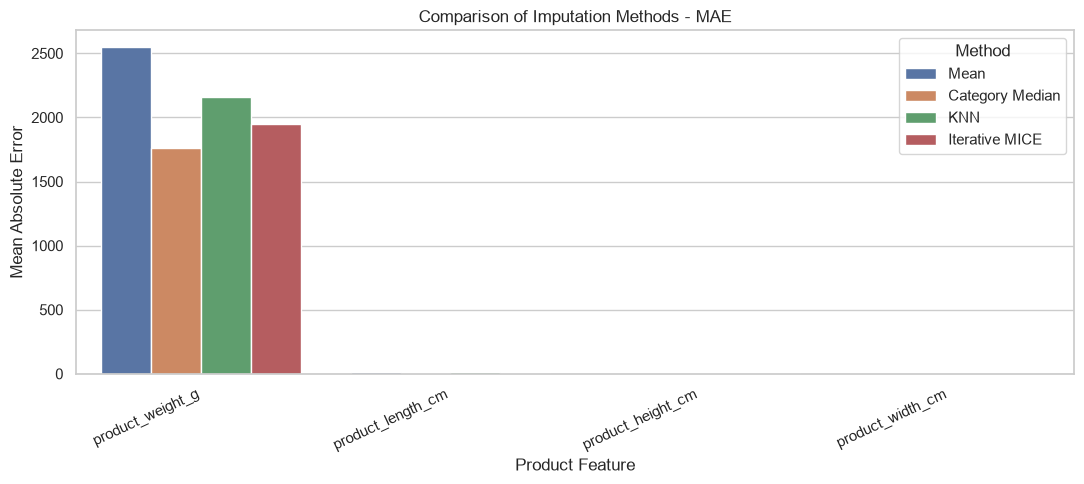

In [50]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=imputation_results_df,
    x="Feature",
    y="MAE",
    hue="Method"
)

plt.title("Comparison of Imputation Methods - MAE")
plt.xlabel("Product Feature")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 5.9 Visualize RMSE Comparison

RMSE gives greater weight to large prediction errors because the errors are squared before averaging. A lower RMSE indicates fewer or smaller large errors.

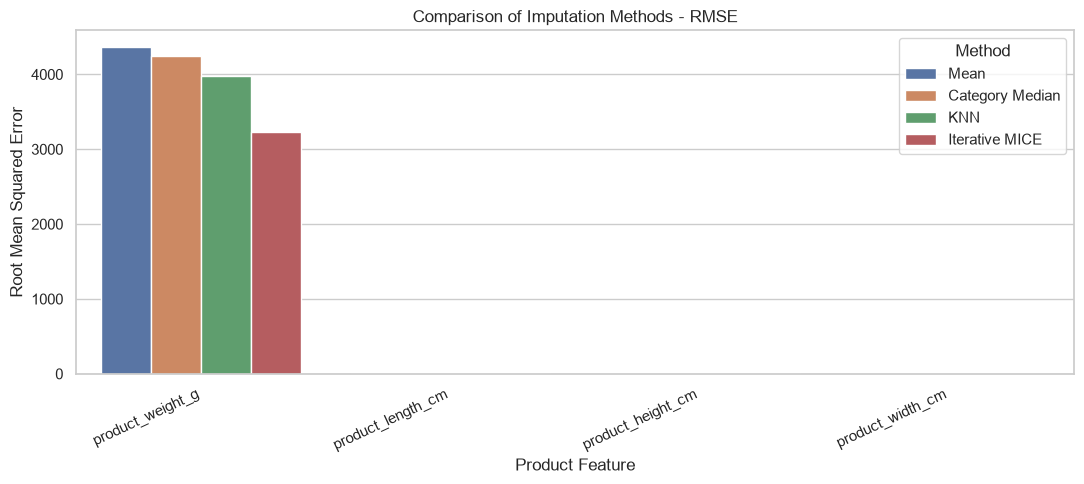

In [51]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=imputation_results_df,
    x="Feature",
    y="RMSE",
    hue="Method"
)

plt.title("Comparison of Imputation Methods - RMSE")
plt.xlabel("Product Feature")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 5.10 Identify the Best Imputation Method for Each Feature

The method with the lowest MAE is identified for each feature. RMSE is also displayed so that the result can be checked against the second error metric.

In [52]:
best_imputation_methods = (
    imputation_results_df
    .sort_values(["Feature", "ME", "RMSE"])
    .groupby("Feature")
    .first()
    .reset_index()
)

print("Best Method for Each Feature (based on lowest MAE)")
display(best_imputation_methods[
    ["Feature", "Method", "MAE", "RMSE"]
].round(4))

Best Method for Each Feature (based on lowest MAE)


,Feature,Method,MAE,RMSE
0,product_height_cm,Iterative MICE,8.1612,11.7740
1,product_length_cm,Iterative MICE,9.2082,13.7017
2,product_weight_g,Category Median,1759.9064,4243.9334
3,product_width_cm,Iterative MICE,6.7382,9.6566


## 6. Overall Observations and Conclusion

### 6.1 Outlier Detection

- IQR detected a large number of outliers, particularly in product weight (15,807).
- MAD identified 33,961 outliers in approval hours, while Z-score generally detected fewer extreme values.
- Isolation Forest and LOF detected 200 outliers each, while Mahalanobis Distance detected 523.
- A total of 235 observations were flagged by at least two multivariate methods, with 65 identified by all three.

### 6.2 Outlier Handling and Sensitivity Analysis

- Winsorization reduced standard deviation across all selected variables while retaining observations.
- The mean changed after Winsorization, whereas the median remained unchanged.
- Log transformation significantly reduced positive skewness in variables such as total price and freight.
- IQR-based removal identified product weight as having the highest number of outliers (15,807).

### 6.3 Missing Value Analysis

- Product category and related attributes had the highest missing values in the product dataset (610 values, 1.85%).
- Review comment titles had 88.29% missing values, while review messages had 58.67%.
- Customers giving 1-star ratings had the highest comment-writing percentage (77.56%).
- The Chi-Square test showed a significant association between comment availability and delivery lateness (p-value < 0.05).
- Logistic Regression achieved 58% accuracy and an F1-score of 0.4735, indicating limited predictive performance.

### 6.4 Imputation Experiment

- Four imputation methods (Mean, Category Median, KNN and Iterative MICE) were compared using MAE and RMSE.
-  Category Median achieved the lowest MAE for product weight (1759.91), while Iterative MICE achieved the lowest RMSE (3228.18).
- Iterative MICE performed best for product length, height and width in both MAE and RMSE.
- Overall, Iterative MICE performed best across three out of four features based on MAE and across all four features based on RMS

### 6.5 Final Conclusion

The analysis investigated outliers, missing values and data reliability in the Olist dataset. Different outlier detection and handling techniques were compared, and missing review comments were analyzed using statistical testing and Logistic Regression. The masking experiment identified suitable imputation methods for product attributes using MAE and RMSE.

These findings help improve data quality and prepare reliable datasets for further statistical analysis, dimensionality reduction and seller clustering in the DELTA project.